# 03.7 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/03-classification/07-roc-auc-threshold/solutions.ipynb)

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

ten = pd.DataFrame({
    "customer": list("ABCDEFGHIJ"),
    "p":  [0.95, 0.85, 0.80, 0.70, 0.60, 0.55, 0.40, 0.30, 0.20, 0.10],
    "y":  [1, 1, 0, 1, 0, 1, 0, 1, 0, 0],
})
ten

,customer,p,y
0,A,0.95,1
1,B,0.85,1
2,C,0.80,0
3,D,0.70,1
4,E,0.60,0
5,F,0.55,1
6,G,0.40,0
7,H,0.30,1
8,I,0.20,0
9,J,0.10,0


In [2]:
def counts(y, p, t):
    """TP, FP, FN, TN when flagging churn for p >= t."""
    y, pred = np.asarray(y), (np.asarray(p) >= t).astype(int)
    TP = int(((y == 1) & (pred == 1)).sum()); FP = int(((y == 0) & (pred == 1)).sum())
    FN = int(((y == 1) & (pred == 0)).sum()); TN = int(((y == 0) & (pred == 0)).sum())
    return TP, FP, FN, TN

def cost(y, p, t, c_voucher=5, c_lost=60):
    TP, FP, FN, TN = counts(y, p, t)
    return c_voucher * (TP + FP) + c_lost * FN

## Exercise 1

At $t = 0.65$ the flagged customers are A, B, C, D. TP = 3 (A, B, D), FP = 1 (C), FN = 2 (F, H), TN = 4. TPR = 3/5 = 0.6, FPR = 1/5 = 0.2. Cost = 5 × 4 + 60 × 2 = £140.

The point (0.2, 0.6) sits between (0, 0.2) and (0.4, 0.8) on the curve.

In [3]:
TP, FP, FN, TN = counts(ten["y"], ten["p"], 0.65)
print(TP, FP, FN, TN, "TPR", TP/(TP+FN), "FPR", FP/(FP+TN), "cost £", cost(ten["y"], ten["p"], 0.65))

3 1 2 4 TPR 0.6 FPR 0.2 cost £ 140


## Exercise 2

New scores: C (stayer) = 0.30, H (churner) = 0.80. Stayers are now 0.60 (E), 0.40 (G), 0.30 (C), 0.20 (I), 0.10 (J).

- A 0.95 → 5, B 0.85 → 5, H 0.80 → 5, D 0.70 → 5, F 0.55 → 4 (beats G, C, I, J; loses to E)

Total 24/25 → **AUC = 0.96**. One swap of a badly-ranked pair fixed almost everything, because C and H were the two most "wrong" scores.

In [4]:
from sklearn.metrics import roc_auc_score
swapped = ten.copy()
swapped.loc[swapped["customer"] == "C", "p"] = 0.30
swapped.loc[swapped["customer"] == "H", "p"] = 0.80
print("AUC after swap:", roc_auc_score(swapped["y"], swapped["p"]))

AUC after swap: 0.9600000000000001


## Exercise 3

In [5]:
for t in [0.90, 0.50, 0.25, 0.00]:
    print(f"t={t:.2f}  cost £{cost(ten['y'], ten['p'], t, c_voucher=20):>4}")

t=0.90  cost £ 260
t=0.50  cost £ 180
t=0.25  cost £ 160
t=0.00  cost £ 200


At £20 per voucher: £260, £180, £160, £200. The cheapest is still 0.25 (£160), but "everyone" (£200) is now worse than it, and the gap between 0.25 and 0.5 has narrowed. Dearer false alarms push the best threshold *up*; here it did not move past 0.25 because the model's ranking is good enough that the eighth flag (H, a real churner) still pays for itself.

## Exercise 4

In [6]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import sys, pandas as pd, numpy as np
sys.path.insert(0, str(data_path("download.py").parent))
from download import ensure_online_retail
from sklearn.model_selection import train_test_split

xlsx = ensure_online_retail()
csv = xlsx.with_name("online_retail_2010_2011.csv")          # fast cache written by lesson 01.3
raw = pd.read_csv(csv, parse_dates=["InvoiceDate"]) if csv.exists() else pd.read_excel(xlsx, sheet_name="Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])

features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
X_train, X_test, y_train, y_test = train_test_split(
    cust[features], cust["churned"], test_size=0.25, random_state=42, stratify=cust["churned"])
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}, "
      f"train {len(X_train):,} / test {len(X_test):,}")

3,317 customers, churn rate 43.6%, train 2,487 / test 830


lost customer £ 20: best threshold 0.25, cost £3,645
lost customer £ 60: best threshold 0.14, cost £3,875
lost customer £150: best threshold 0.05, cost £3,955


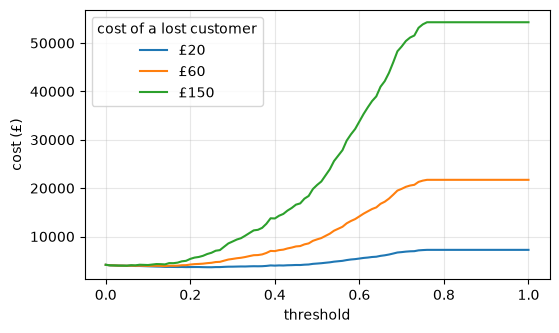

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)
proba_test = logreg.predict_proba(X_test)[:, 1]          # P(churn) for each test customer
pred_test = logreg.predict(X_test)                        # same as (proba_test >= 0.5)

ts = np.linspace(0, 1, 101)
plt.figure(figsize=(6, 3.5))
for c_lost in [20, 60, 150]:
    cs = np.array([cost(y_test, proba_test, t, c_lost=c_lost) for t in ts])
    print(f"lost customer £{c_lost:>3}: best threshold {ts[cs.argmin()]:.2f}, cost £{cs.min():,}")
    plt.plot(ts, cs, label=f"£{c_lost}")
plt.xlabel("threshold"); plt.ylabel("cost (£)"); plt.legend(title="cost of a lost customer"); plt.grid(alpha=.3); plt.show()

As the cost of a lost customer rises, the best threshold falls: a missed churner becomes so expensive that it is worth sending many more vouchers to avoid one. At £20 the two mistakes are closer in cost and the threshold sits higher.